# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  #  только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True   # одинаковые числа при повторном прогоне
torch.backends.cudnn.benchmark = False
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')  # UTF-8 обязательно (Windows-локаль cp1251)
print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS),
       'torch': torch.__version__, 'numpy': np.__version__})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts', 'torch': '2.14.1+cu126', 'numpy': '2.4.6'}


In [2]:
# Проверка зависимостей лабы 15: torch, numpy, matplotlib.
# Сеть НЕ используется: 2D-данные генерируются локально с фиксированными seed; diffusers для этой лабы не нужен.
import importlib.util
_need = {'torch': 'torch', 'numpy': 'numpy', 'matplotlib': 'matplotlib'}
missing = [k for k in _need if importlib.util.find_spec(k) is None]
if missing:
    raise ImportError('Установите недостающее и перезапустите ячейку:  pip install ' + ' '.join(_need[k] for k in missing))
import torch, numpy, matplotlib
_info = {'torch': torch.__version__, 'numpy': numpy.__version__, 'matplotlib': matplotlib.__version__,
         'device': 'cuda' if torch.cuda.is_available() else 'cpu'}
if torch.cuda.is_available():
    _p = torch.cuda.get_device_properties(0)
    _info['gpu'] = f'{_p.name} | cc {_p.major}.{_p.minor}'
    _info['gpu_note'] = 'GPU ускорит обучение; задача 2D, полный прогон занимает минуты даже на CPU'
else:
    _info['gpu_note'] = 'CUDA недоступна - допустимо: полный прогон 2D-задачи идёт на CPU за минуты'
print('Версии:', _info)

Версии: {'torch': '2.14.1+cu126', 'numpy': '2.4.6', 'matplotlib': '3.11.2', 'device': 'cuda', 'gpu': 'NVIDIA GeForce GTX 1050 Ti | cc 6.1', 'gpu_note': 'GPU ускорит обучение; задача 2D, полный прогон занимает минуты даже на CPU'}


### Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

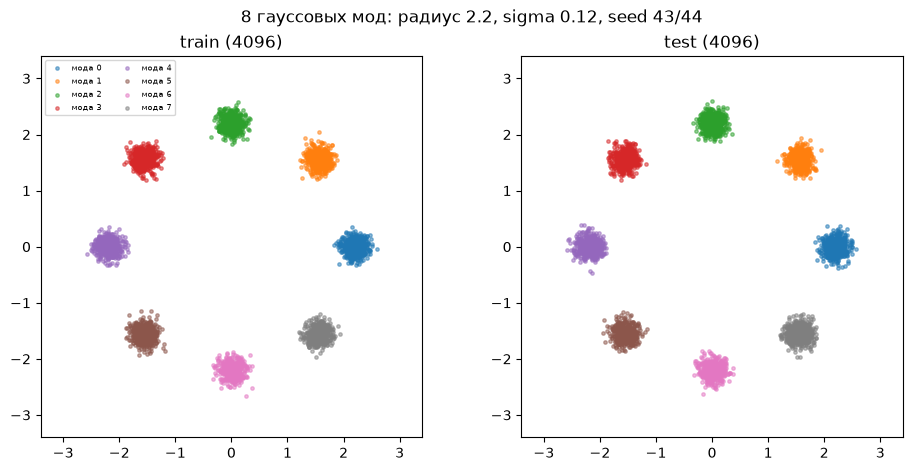

ЗАДАНИЕ 1 OK: train 4096 / test 4096 точек, 8 мод (радиус 2.2, sigma 0.12); моды train 487-534 точек, test 483-558; seed 43/44; -> lab15_data_report.json + lab15_data.png


In [3]:
# ЗАДАНИЕ 1 - восьмимодальное 2D-распределение: независимые train/test выборки, фиксированные seed и центры мод.
N_TRAIN = 1_000 if FAST_DEV_RUN else 4096     # train-точки (одни и те же для flow, VP, coupling и бонуса)
N_TEST = 1_000 if FAST_DEV_RUN else 4096      # независимый test: ТОЛЬКО для метрик сэмплеров
R_MODES, MODE_STD = 2.2, 0.12                 # радиус окружности мод и разброс внутри моды
NOISE_STD = 1.0                               # prior N(0, I) общий для flow, VP, coupling и бонуса

_angles = torch.arange(8, dtype=torch.float64) * (2 * torch.pi / 8)
MODE_CENTERS = torch.stack([torch.cos(_angles), torch.sin(_angles)], 1) * R_MODES   # (8, 2)
assert MODE_CENTERS.shape == (8, 2) and MODE_CENTERS.std().item() > 0.5, 'центры мод должны быть различимы'

def sample_mixture(n, seed):
    g = torch.Generator().manual_seed(seed)
    mode = torch.randint(0, 8, (n,), generator=g)
    pts = MODE_CENTERS.float()[mode] + MODE_STD * torch.randn(n, 2, generator=g)
    return pts, mode

X_TRAIN, TRAIN_MODE = sample_mixture(N_TRAIN, SEED + 1)
X_TEST, TEST_MODE = sample_mixture(N_TEST, SEED + 2)
assert X_TRAIN.shape == (N_TRAIN, 2) and X_TEST.shape == (N_TEST, 2)
assert not torch.equal(X_TRAIN[:256], X_TEST[:256]), 'train и test должны быть независимыми выборками (разные seed)'
_probe, _pm = sample_mixture(N_TRAIN, SEED + 1)   # повтор ТОЙ ЖЕ размерности: потоки RNG зависят от размера тензора
assert torch.equal(_probe, X_TRAIN) and torch.equal(_pm, TRAIN_MODE), 'генерация train невоспроизводима'
_train_counts = torch.bincount(TRAIN_MODE, minlength=8)
_test_counts = torch.bincount(TEST_MODE, minlength=8)
assert int(_train_counts.min()) > 0 and int(_test_counts.min()) > 0, 'пустая мода в выборке'

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6), constrained_layout=True)
for _ax, _pts, _mode, _title in [(axes[0], X_TRAIN, TRAIN_MODE, f'train ({N_TRAIN})'),
                                 (axes[1], X_TEST, TEST_MODE, f'test ({N_TEST})')]:
    for _k in range(8):
        _sel = _mode == _k
        _ax.scatter(_pts[_sel, 0], _pts[_sel, 1], s=6, alpha=0.5, label=f'мода {_k}')
    _ax.set_title(_title); _ax.set_aspect('equal'); _ax.set_xlim(-3.4, 3.4); _ax.set_ylim(-3.4, 3.4)
axes[0].legend(fontsize=6, ncol=2, loc='upper left')
fig.suptitle(f'8 гауссовых мод: радиус {R_MODES}, sigma {MODE_STD}, seed {SEED + 1}/{SEED + 2}')
fig.savefig(ARTIFACTS / 'lab15_data.png', dpi=130)
plt.show(); plt.close(fig)

save_json('lab15_data_report.json', {'n_train': N_TRAIN, 'n_test': N_TEST, 'radius': R_MODES,
          'mode_std': MODE_STD, 'noise_std': NOISE_STD, 'seed_train': SEED + 1, 'seed_test': SEED + 2,
          'train_mode_counts': _train_counts.tolist(), 'test_mode_counts': _test_counts.tolist(),
          'centers': [[round(v, 4) for v in row] for row in MODE_CENTERS.tolist()],
          'note': 'train и test - независимые выборки одного распределения; test используется только в метриках сэмплеров'})
print(f'ЗАДАНИЕ 1 OK: train {N_TRAIN} / test {N_TEST} точек, 8 мод (радиус {R_MODES}, sigma {MODE_STD}); '
      f'моды train {_train_counts.min().item()}-{_train_counts.max().item()} точек, test '
      f'{_test_counts.min().item()}-{_test_counts.max().item()}; seed {SEED + 1}/{SEED + 2}; '
      f'-> lab15_data_report.json + lab15_data.png')

### Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

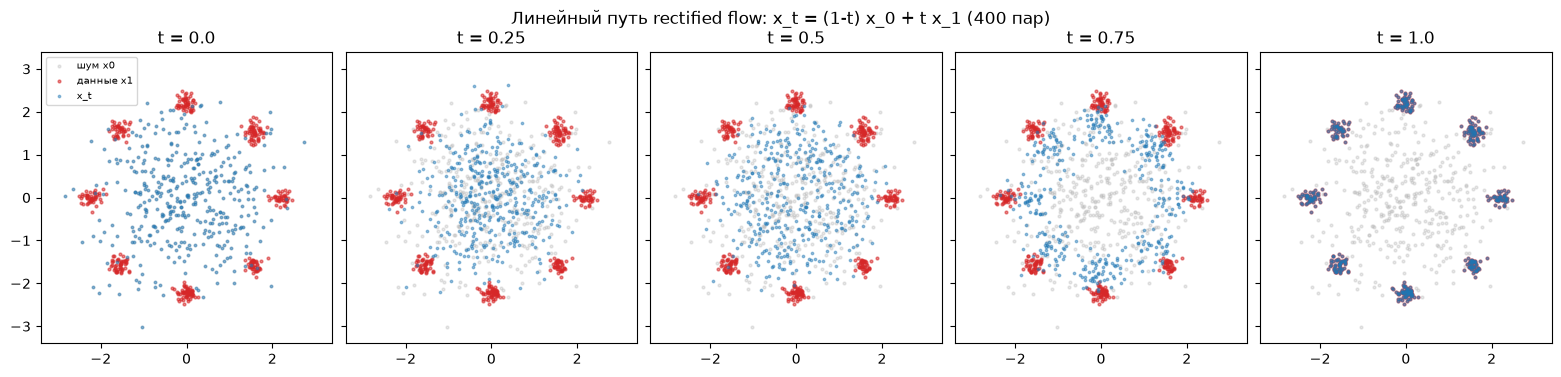

ЗАДАНИЕ 2 OK: VelocityMLP (33794 параметров, вход (x, y, t), SiLU x3) определён; линейный путь на 400 парах (шум N(0, 1.0I) -> train-точки), срезы t = 0/0.25/0.5/0.75/1 -> lab15_paths.png; таргет v* = x1 - x0 -> lab15_paths_report.json


In [4]:
# ЗАДАНИЕ 2 - MLP векторного поля и визуализация линейного пути x_t = (1-t) x_0 + t x_1.
import torch.nn as nn

class VelocityMLP(nn.Module):
    # v(x, t): вход (x, y, t) -> скорость (2D); use_time=False - вариант бонуса (вход без t).
    def __init__(self, width=128, use_time=True):
        super().__init__()
        self.use_time = use_time
        in_dim = 3 if use_time else 2
        self.net = nn.Sequential(nn.Linear(in_dim, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, 2))
    def forward(self, x, t):
        if self.use_time:
            x = torch.cat([x, t], dim=1)
        return self.net(x)

_m = VelocityMLP()
assert _m(torch.zeros(4, 2), torch.zeros(4, 1)).shape == (4, 2)
assert VelocityMLP(use_time=False)(torch.zeros(4, 2), torch.zeros(4, 1)).shape == (4, 2)
N_PARAMS = sum(p.numel() for p in _m.parameters())

_g = torch.Generator().manual_seed(SEED + 3)
_idx = torch.randperm(N_TRAIN, generator=_g)[:400]
X1_SHOW = X_TRAIN[_idx]                              # (400, 2) данные
X0_SHOW = torch.randn(400, 2, generator=_g)          # (400, 2) шум N(0, I) - как в обучении
T_SHOW = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axes = plt.subplots(1, len(T_SHOW), figsize=(3.1 * len(T_SHOW), 3.6), sharex=True, sharey=True,
                         constrained_layout=True)
for _ax, _t in zip(axes, T_SHOW):
    _xt = (1 - _t) * X0_SHOW + _t * X1_SHOW
    _ax.scatter(X0_SHOW[:, 0], X0_SHOW[:, 1], s=4, c='#bbbbbb', alpha=0.35, label='шум x0')
    _ax.scatter(X1_SHOW[:, 0], X1_SHOW[:, 1], s=4, c='#d62728', alpha=0.55, label='данные x1')
    _ax.scatter(_xt[:, 0], _xt[:, 1], s=3, c='#1f77b4', alpha=0.45, label='x_t')
    _ax.set_title(f't = {_t}'); _ax.set_aspect('equal'); _ax.set_xlim(-3.4, 3.4); _ax.set_ylim(-3.4, 3.4)
axes[0].legend(fontsize=7, loc='upper left')
fig.suptitle('Линейный путь rectified flow: x_t = (1-t) x_0 + t x_1 (400 пар)')
fig.savefig(ARTIFACTS / 'lab15_paths.png', dpi=130)
plt.show(); plt.close(fig)

save_json('lab15_paths_report.json', {'n_pairs_shown': 400, 'noise_std': NOISE_STD,
          'mlp': 'Linear(3->128)+SiLU x3 -> Linear(128->2)', 'n_params': N_PARAMS,
          'use_time_variant': 'бонус: use_time=False (вход (x, y) без t)',
          'note': 'таргет скорости на линейном пути: v* = x1 - x0'})
print(f'ЗАДАНИЕ 2 OK: VelocityMLP ({N_PARAMS} параметров, вход (x, y, t), SiLU x3) определён; линейный путь '
      f'на 400 парах (шум N(0, {NOISE_STD}I) -> train-точки), срезы t = 0/0.25/0.5/0.75/1 '
      f'-> lab15_paths.png; таргет v* = x1 - x0 -> lab15_paths_report.json')

### Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

In [5]:
# ЗАДАНИЕ 3 - вторая модель для VP diffusion: отдельный MLP и два независимых оптимизатора.
model_flow = VelocityMLP()      # rectified flow: предсказывает скорость v(x_t, t)
model_vp = VelocityMLP()        # VP diffusion: предсказывает добавленный шум eps(x_t, t)
assert sum(p.numel() for p in model_flow.parameters()) == sum(p.numel() for p in model_vp.parameters()) == N_PARAMS, \
    'у честного сравнения модели обязаны быть одинакового размера'
LR = 1e-3
opt_flow = torch.optim.Adam(model_flow.parameters(), lr=LR)
opt_vp = torch.optim.Adam(model_vp.parameters(), lr=LR)
assert opt_flow.param_groups[0]['lr'] == opt_vp.param_groups[0]['lr'] and opt_flow is not opt_vp
save_json('lab15_models_report.json', {'flow': 'VelocityMLP, таргет v* = x1 - x0',
          'vp': 'VelocityMLP, таргет eps', 'n_params_each': N_PARAMS, 'optimizer': 'Adam', 'lr': LR,
          'independent_optimizers': True,
          'note': 'архитектура и размер одинаковы; сравнивается качество распределения сэмплов, а не loss'})
print(f'ЗАДАНИЕ 3 OK: model_flow и model_vp ({N_PARAMS} параметров каждая, архитектура идентична), '
      f'два независимых Adam (lr {LR}); flow учит скорость v(x_t, t), VP учит шум eps(x_t, t) '
      f'-> lab15_models_report.json')

ЗАДАНИЕ 3 OK: model_flow и model_vp (33794 параметров каждая, архитектура идентична), два независимых Adam (lr 0.001); flow учит скорость v(x_t, t), VP учит шум eps(x_t, t) -> lab15_models_report.json


### Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

In [6]:
# ЗАДАНИЕ 4 - обучение flow и VP на ОДНОЙ train-выборке при равном бюджете optimizer updates.
# Общий план: одинаковые батчи-индексы, одинаковые t и одинаковый шум на каждом шаге; различие - только путь и таргет.
STEPS = 3 if FAST_DEV_RUN else 3000
BATCH = 64 if FAST_DEV_RUN else 256
VP_T_MAX = 0.9   # cap по теории: alpha_t = cos(pi t / 2) > 0; при t=1 деление на alpha сингулярно

_sched = np.random.RandomState(SEED + 100)      # общее расписание батчей для всех моделей лабы
BATCH_IDX = [_sched.permutation(N_TRAIN)[:BATCH].copy() for _ in range(STEPS)]

def vp_alpha_sigma(t):
    return torch.cos(torch.pi * t / 2), torch.sin(torch.pi * t / 2)

def train_step(model, optimizer, step, kind, paired=None):
    # один optimizer update; kind='flow' | 'vp'; paired=(x0, x1) - связанный батч (ЗАДАНИЕ 9).
    model.train(); optimizer.zero_grad(set_to_none=True)
    _g = torch.Generator().manual_seed(1_000_003 + step)   # одинаковые t на шаге у всех моделей
    t = torch.rand(BATCH, 1, generator=_g) if kind == 'flow' else VP_T_MAX * torch.rand(BATCH, 1, generator=_g)
    if paired is None:
        x1 = X_TRAIN[torch.from_numpy(BATCH_IDX[step])]
        x0 = torch.randn(BATCH, 2, generator=_g)
    else:
        x0, x1 = paired
    if kind == 'flow':
        xt = (1 - t) * x0 + t * x1
        target = x1 - x0                                   # линейный путь: v* = x1 - x0
    else:
        _a, _s = vp_alpha_sigma(t)
        xt = _a * x1 + _s * x0
        target = x0                                        # VP: предсказываем eps
    dev = next(model.parameters()).device
    pred = model(xt.to(dev), t.to(dev))
    loss = torch.nn.functional.mse_loss(pred, target.to(dev))
    loss.backward(); optimizer.step()
    return float(loss.detach())

model_flow.to(DEVICE); model_vp.to(DEVICE)
history_flow, history_vp = [], []
_t0 = time.time()
for _s in range(STEPS):
    history_flow.append(train_step(model_flow, opt_flow, _s, 'flow'))
    history_vp.append(train_step(model_vp, opt_vp, _s, 'vp'))
TRAIN_TIME = round(time.time() - _t0, 1)
assert all(np.isfinite(history_flow)) and all(np.isfinite(history_vp)), 'NaN в loss'
_tail = lambda h: round(sum(h[-100:]) / max(1, len(h[-100:])), 6)
print(f'ЗАДАНИЕ 4 OK: {STEPS} optimizer updates КАЖДОЙ модели (batch {BATCH}) на одной train-выборке, '
      f'общие батчи/t/шум; loss flow: {round(history_flow[0], 4)} -> {_tail(history_flow)} (средн. 100 шагов); '
      f'loss VP: {round(history_vp[0], 4)} -> {_tail(history_vp)}; {TRAIN_TIME} c; '
      f'loss НЕ сравниваются напрямую (разные таргеты: v* против eps)')

ЗАДАНИЕ 4 OK: 3000 optimizer updates КАЖДОЙ модели (batch 256) на одной train-выборке, общие батчи/t/шум; loss flow: 3.6075 -> 2.046918 (средн. 100 шагов); loss VP: 1.0666 -> 0.440544; 13.6 c; loss НЕ сравниваются напрямую (разные таргеты: v* против eps)


### Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

In [7]:
# ЗАДАНИЕ 5 - фиксация траектории обучения: история лоссов внутри checkpoint (resume) + JSON-лог.
def make_ckpt(model, optimizer, hist, extra=None):
    payload = {'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'step': len(hist),
               'loss_history': hist,
               'config': {'steps': STEPS, 'batch': BATCH, 'lr': LR, 'n_train': N_TRAIN, 'seed': SEED,
                          'vp_t_max': VP_T_MAX}}
    if extra:
        payload.update(extra)
    return payload

CKPT_DIR = ARTIFACTS / 'lab15'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(make_ckpt(model_flow, opt_flow, history_flow), CKPT_DIR / 'ckpt_flow.pt')
torch.save(make_ckpt(model_vp, opt_vp, history_vp), CKPT_DIR / 'ckpt_vp.pt')
save_json('lab15_training_log.json', {'steps': STEPS, 'batch': BATCH, 'lr': LR, 'seed': SEED,
          'vp_t_max': VP_T_MAX, 'loss_flow': [round(v, 6) for v in history_flow],
          'loss_vp': [round(v, 6) for v in history_vp], 'train_time_s': TRAIN_TIME,
          'checkpoints': ['lab15/ckpt_flow.pt', 'lab15/ckpt_vp.pt'],
          'note': 'история внутри ckpt: resume продолжает обучение с последнего шага без потери графика loss'})

# resume-проверка: checkpoint, загруженный в свежую модель, даёт те же выходы
_probe_x = torch.randn(64, 2, generator=torch.Generator().manual_seed(SEED + 5))
_probe_t = torch.rand(64, 1, generator=torch.Generator().manual_seed(SEED + 6))
_ckpt = torch.load(CKPT_DIR / 'ckpt_flow.pt', map_location='cpu', weights_only=False)
_fresh = VelocityMLP()
_fresh.load_state_dict(_ckpt['model'])
_fresh.eval(); model_flow.eval()
with torch.no_grad():
    _d = (_fresh(_probe_x, _probe_t) - model_flow.cpu()(_probe_x, _probe_t)).abs().max().item()
model_flow.to(DEVICE)
assert _d < 1e-5, f'resume не совпадает: max|d|={_d}'
assert _ckpt['step'] == STEPS and len(_ckpt['loss_history']) == STEPS, 'история в ckpt неполная'
print(f'ЗАДАНИЕ 5 OK: история {STEPS} шагов x 2 модели сохранена (ckpt_flow.pt / ckpt_vp.pt: model + optimizer '
      f'+ step + loss_history; JSON-лог -> lab15_training_log.json); resume-проверка: выход свежей модели после '
      f'load_state_dict совпадает с обученной (max|d| = {_d:.2e})')

ЗАДАНИЕ 5 OK: история 3000 шагов x 2 модели сохранена (ckpt_flow.pt / ckpt_vp.pt: model + optimizer + step + loss_history; JSON-лог -> lab15_training_log.json); resume-проверка: выход свежей модели после load_state_dict совпадает с обученной (max|d| = 0.00e+00)


### Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

In [8]:
# ЗАДАНИЕ 6 - интеграторы: Euler для flow ODE и обратный шаг VP без сингулярного endpoint; общий шум.
N_EVAL = 1_000 if FAST_DEV_RUN else 4096
EVAL_K_GRID = [1, 2] if FAST_DEV_RUN else [1, 2, 5, 10, 25, 100]

@torch.no_grad()
def euler_flow(model, z, steps):
    # Решение ODE dx/dt = v(x, t) на t из [0, 1] методом Эйлера: x(0) = шум -> x(1) = данные.
    dev = next(model.parameters()).device
    x = z.clone().to(dev)
    for _i in range(steps):
        t = torch.full((len(x), 1), _i / steps, device=dev)
        x = x + (1.0 / steps) * model(x, t)
    return x

@torch.no_grad()
def vp_reverse(model, z, steps, t_max=VP_T_MAX):
    # Обратный процесс VP (DDIM без шума): t от t_max к 0; t_max=0.9 вместо 1 - без сингулярной точки.
    dev = next(model.parameters()).device
    x = z.clone().to(dev)
    ts = torch.linspace(t_max, 0.0, steps + 1)
    for _i in range(steps):
        tc, tn = float(ts[_i]), float(ts[_i + 1])
        eps_hat = model(x, torch.full((len(x), 1), tc, device=dev))
        a_c, s_c = vp_alpha_sigma(torch.tensor(tc))
        a_n, s_n = vp_alpha_sigma(torch.tensor(tn))
        assert a_c.item() > 1e-3, f'сингулярный alpha при t={tc}'    # гарантия отсутствия деления на ~0
        x1_hat = (x - s_c.item() * eps_hat) / a_c.item()
        x = a_n.item() * x1_hat + s_n.item() * eps_hat
    return x

GEN_EVAL = torch.Generator().manual_seed(SEED + 7)     # ОБЩИЙ шум: одинаковый Z для всех сэмплеров лабы
Z_EVAL = torch.randn(N_EVAL, 2, generator=GEN_EVAL)
assert torch.isfinite(Z_EVAL).all() and Z_EVAL.shape == (N_EVAL, 2)
_a09 = vp_alpha_sigma(torch.tensor(VP_T_MAX))[0].item()
assert _a09 > 0.15, f'alpha(t_max)={_a09} слишком мал'
save_json('lab15_integrators_report.json', {'n_eval': N_EVAL, 'z_seed': SEED + 7, 'k_grid': EVAL_K_GRID,
          'flow': 'Euler: x_{i+1} = x_i + dt * v(x_i, i*dt), dt = 1/K, t: 0 -> 1',
          'vp': f'DDIM-детерминированный обратный шаг, t: {VP_T_MAX} -> 0; t_max = {VP_T_MAX} вместо 1 '
                f'(alpha({VP_T_MAX}) = {round(_a09, 4)} > 0 - сингулярная точка t=1 исключена)',
          'shared_noise': 'одинаковый Z для flow/VP/coupling/бонуса - сравнение сэмплеров на одних стартовых точках'})
print(f'ЗАДАНИЕ 6 OK: euler_flow (t: 0 -> 1) и vp_reverse (t: {VP_T_MAX} -> 0, DDIM без шума, без деления на '
      f'alpha=0); общий шум Z ({N_EVAL}x2, seed {SEED + 7}) создан один для всех сэмплеров; сетка K = {EVAL_K_GRID} '
      f'-> lab15_integrators_report.json')

ЗАДАНИЕ 6 OK: euler_flow (t: 0 -> 1) и vp_reverse (t: 0.9 -> 0, DDIM без шума, без деления на alpha=0); общий шум Z (4096x2, seed 49) создан один для всех сэмплеров; сетка K = [1, 2, 5, 10, 25, 100] -> lab15_integrators_report.json


### Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

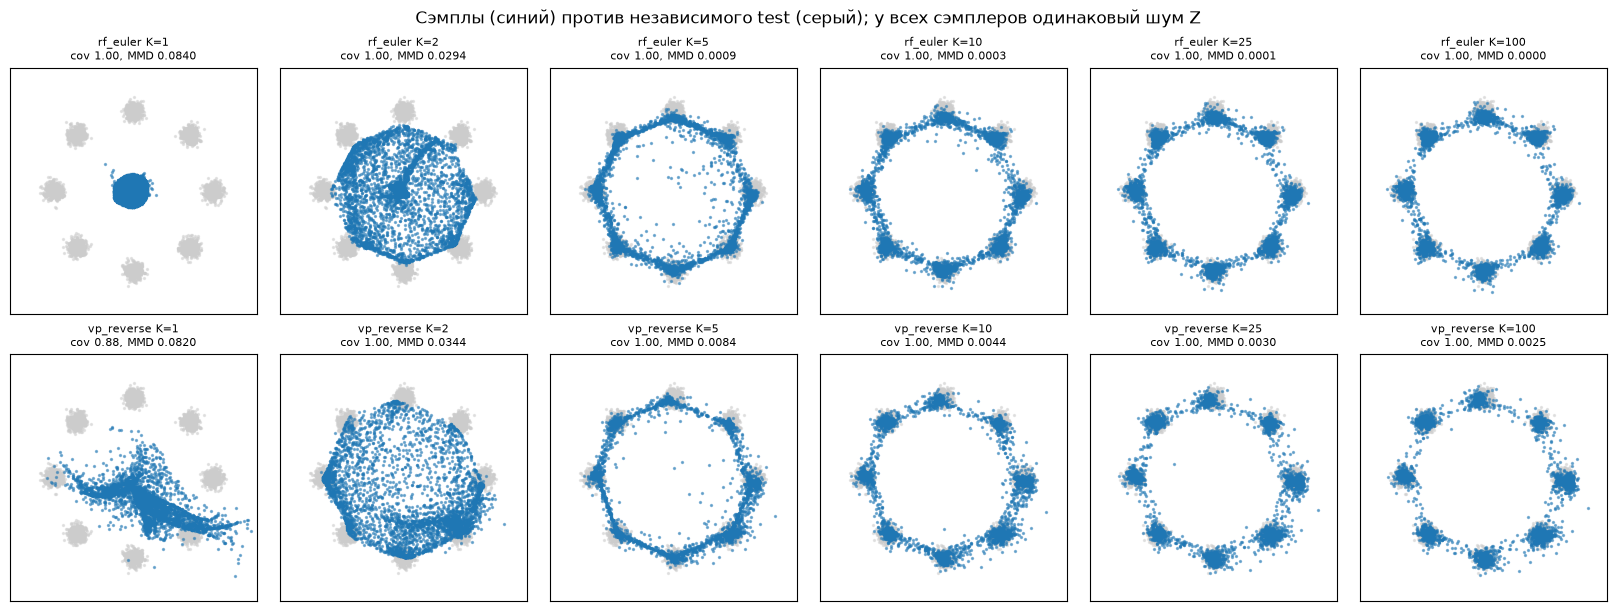

ЗАДАНИЕ 7 OK: метрики по независимому test:
  rf_euler@1       покрытие 1.000 (8/8 мод, мин 378) MMD2 0.08399  ср.dist до test 1.604  0.02 c
  rf_euler@2       покрытие 1.000 (8/8 мод, мин 370) MMD2 0.02941  ср.dist до test 0.701  0.00 c
  rf_euler@5       покрытие 1.000 (8/8 мод, мин 446) MMD2 0.00089  ср.dist до test 0.092  0.01 c
  rf_euler@10      покрытие 1.000 (8/8 мод, мин 429) MMD2 0.00032  ср.dist до test 0.053  0.02 c
  rf_euler@25      покрытие 1.000 (8/8 мод, мин 419) MMD2 0.00010  ср.dist до test 0.039  0.04 c
  rf_euler@100     покрытие 1.000 (8/8 мод, мин 411) MMD2 0.00003  ср.dist до test 0.033  0.15 c
  vp_reverse@1     покрытие 0.875 (7/8 мод, мин 27) MMD2 0.08196  ср.dist до test 0.990  0.01 c
  vp_reverse@2     покрытие 1.000 (8/8 мод, мин 211) MMD2 0.03435  ср.dist до test 0.309  0.00 c
  vp_reverse@5     покрытие 1.000 (8/8 мод, мин 301) MMD2 0.00842  ср.dist до test 0.070  0.00 c
  vp_reverse@10    покрытие 1.000 (8/8 мод, мин 362) MMD2 0.00444  ср.dist до test 0

In [9]:
# ЗАДАНИЕ 7 - покрытие мод и качество распределения сэмплов относительно независимого test (+ PNG).
def mode_stats(pts):
    # Точка относится к ближайшему центру моды; мода покрыта, если в ней >= 1% сэмплов.
    d = torch.cdist(pts, MODE_CENTERS.float())
    assign = d.argmin(1)
    counts = torch.bincount(assign, minlength=8)
    thr = max(1, int(0.01 * len(pts)))
    covered = int((counts >= thr).sum())
    return {'assign': assign, 'counts': counts.tolist(), 'threshold': thr, 'covered_modes': covered,
            'coverage': covered / 8, 'min_mode_count': int(counts.min()), 'max_mode_count': int(counts.max()),
            'mean_dist_to_center': float(d.min(1).values.mean())}

_test_sub = X_TEST[torch.randperm(N_TEST, generator=torch.Generator().manual_seed(SEED + 21))[:2048]]
_bw2 = torch.cdist(_test_sub, _test_sub)
_bw = _bw2[_bw2 > 0].median().item()                    # median-heuristic ширина RBF-ядра

def mmd_rbf(a, b, bw):
    # Несмещённый MMD^2 с гауссовым ядром: a - сэмплы, b - test-подвыборка.
    def _k(x, y):
        return torch.exp(-torch.cdist(x, y) ** 2 / (2 * bw ** 2))
    n, m = len(a), len(b)
    ka, kb, kab = _k(a, a), _k(b, b), _k(a, b)
    return float((ka.sum() - ka.diagonal().sum()) / (n * (n - 1))
                 + (kb.sum() - kb.diagonal().sum()) / (m * (m - 1)) - 2 * kab.mean())

def mean_nn_to_test(pts, chunk=512):
    # Среднее расстояние от сэмпла до ближайшей test-точки (чанками, без scipy).
    parts = []
    for _i in range(0, len(pts), chunk):
        parts.append(torch.cdist(pts[_i:_i + chunk], X_TEST).min(1).values)
    return float(torch.cat(parts).mean())

def eval_sampler(name, pts, seconds):
    ms = mode_stats(pts)
    row = {'sampler': name, 'coverage': round(ms['coverage'], 4), 'covered_modes': ms['covered_modes'],
           'min_mode_count': ms['min_mode_count'], 'max_mode_count': ms['max_mode_count'],
           'mean_dist_to_center': round(ms['mean_dist_to_center'], 4),
           'mmd2': round(mmd_rbf(pts[:2048], _test_sub, _bw), 6),
           'mean_nn_to_test': round(mean_nn_to_test(pts[:2048]), 4), 'time_s': round(seconds, 3)}
    return row, ms

sampler_rows, mode_maps = [], {}
for _name, _model, _fn in [('rf_euler', model_flow, euler_flow), ('vp_reverse', model_vp, vp_reverse)]:
    for _k in EVAL_K_GRID:
        if torch.cuda.is_available(): torch.cuda.synchronize()
        _t = time.time()
        _pts = _fn(_model, Z_EVAL, _k).cpu()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        _row, _ms = eval_sampler(f'{_name}@{_k}', _pts, time.time() - _t)
        sampler_rows.append(_row)
        mode_maps[f'{_name}@{_k}'] = _pts
assert all(np.isfinite(r['mmd2']) and np.isfinite(r['mean_nn_to_test']) for r in sampler_rows), 'NaN в метриках'
_rf_last = max((r for r in sampler_rows if r['sampler'].startswith('rf')), key=lambda r: int(r['sampler'].split('@')[1]))
if _rf_last['coverage'] < 1.0:
    print(f'  ВНИМАНИЕ: лучший RF покрывает {_rf_last["covered_modes"]}/8 мод - проверьте обучение')

fig, axes = plt.subplots(2, len(EVAL_K_GRID), figsize=(2.7 * len(EVAL_K_GRID), 6.0), constrained_layout=True)
axes = np.asarray(axes).reshape(2, -1)
for _r, _name in enumerate(['rf_euler', 'vp_reverse']):
    for _c, _k in enumerate(EVAL_K_GRID):
        _pts = mode_maps[f'{_name}@{_k}']
        _row = next(x for x in sampler_rows if x['sampler'] == f'{_name}@{_k}')
        _ax = axes[_r][_c]
        _ax.scatter(X_TEST[:, 0], X_TEST[:, 1], s=2, c='#cccccc', alpha=0.45)
        _ax.scatter(_pts[:, 0], _pts[:, 1], s=2, c='#1f77b4', alpha=0.5)
        _ax.set_title(f'{_name} K={_k}\ncov {_row["coverage"]:.2f}, MMD {_row["mmd2"]:.4f}', fontsize=8)
        _ax.set_aspect('equal'); _ax.set_xlim(-3.4, 3.4); _ax.set_ylim(-3.4, 3.4)
        _ax.set_xticks([]); _ax.set_yticks([])
fig.suptitle('Сэмплы (синий) против независимого test (серый); у всех сэмплеров одинаковый шум Z')
fig.savefig(ARTIFACTS / 'lab15_samples.png', dpi=120)
plt.show(); plt.close(fig)

save_json('lab15_sampler_metrics.json', {'rows': sampler_rows, 'n_eval': N_EVAL, 'k_grid': EVAL_K_GRID,
          'mode_threshold': max(1, int(0.01 * N_EVAL)),
          'mmd': f'несмещённый MMD^2, RBF, bw = median(test) = {round(_bw, 4)}',
          'note': 'все метрики - по фактическим точкам сэмплов против независимого test; train loss не используется'})
print('ЗАДАНИЕ 7 OK: метрики по независимому test:')
for _r in sampler_rows:
    print(f"  {_r['sampler']:<16} покрытие {_r['coverage']:.3f} ({_r['covered_modes']}/8 мод, мин {_r['min_mode_count']}"
          f") MMD2 {_r['mmd2']:.5f}  ср.dist до test {_r['mean_nn_to_test']:.3f}  {_r['time_s']:.2f} c")
print(f'строки -> lab15_sampler_metrics.json, панели -> lab15_samples.png')

### Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

In [10]:
# ЗАДАНИЕ 8 - сводная таблица выборок: эмпирические метрики и время; train loss сознательно не сравнивается.
_main = max((r['sampler'] for r in sampler_rows if r['sampler'].startswith('rf')),
            key=lambda s: int(s.split('@')[1]))
_worst_src = mode_maps[_main]
_d_test = torch.cdist(_worst_src, X_TEST).min(1).values
_worst_idx = _d_test.argsort(descending=True)[:5]
worst5 = []
for _rank, _i in enumerate(_worst_idx, 1):
    _dm = torch.cdist(_worst_src[_i:_i + 1], MODE_CENTERS.float())
    worst5.append({'rank': _rank, 'point': [round(v, 4) for v in _worst_src[_i].tolist()],
                   'dist_to_nearest_test': round(float(_d_test[_i]), 4),
                   'nearest_mode': int(_dm.argmin()), 'dist_to_nearest_mode': round(float(_dm.min()), 4)})
save_json('lab15_worst5.json', {'criterion': f'5 сэмплов {_main}, наиболее удалённых от ближайшей test-точки; '
                                'значения фактические', 'worst': worst5})
save_json('lab15_samplers_summary.json', {'rows': sampler_rows, 'n_eval': N_EVAL, 'k_grid': EVAL_K_GRID,
          'main_sampler': _main, 'worst5_file': 'lab15_worst5.json', 'train_time_s': TRAIN_TIME,
          '_note': 'train losses НЕ сравниваются напрямую: у flow и VP разные таргеты (v* = x1 - x0 против eps); '
                   'качество сравнивается только по сэмплам относительно независимого test'})
print('ЗАДАНИЕ 8 OK: сводная таблица (полный вариант в lab15_samplers_summary.json):')
for _r in sampler_rows:
    print(f"  {_r['sampler']:<16} cov {_r['coverage']:.3f}  MMD2 {_r['mmd2']:.5f}  "
          f"ср.dist {_r['mean_nn_to_test']:.3f}  {_r['time_s']:.2f} c")
print(f"5 худших сэмплов {_main} (макс. расстояние до test) -> lab15_worst5.json; "
      f"loss в сводку не включены - разные таргеты у flow и VP")

ЗАДАНИЕ 8 OK: сводная таблица (полный вариант в lab15_samplers_summary.json):
  rf_euler@1       cov 1.000  MMD2 0.08399  ср.dist 1.604  0.02 c
  rf_euler@2       cov 1.000  MMD2 0.02941  ср.dist 0.701  0.00 c
  rf_euler@5       cov 1.000  MMD2 0.00089  ср.dist 0.092  0.01 c
  rf_euler@10      cov 1.000  MMD2 0.00032  ср.dist 0.053  0.02 c
  rf_euler@25      cov 1.000  MMD2 0.00010  ср.dist 0.039  0.04 c
  rf_euler@100     cov 1.000  MMD2 0.00003  ср.dist 0.033  0.15 c
  vp_reverse@1     cov 0.875  MMD2 0.08196  ср.dist 0.990  0.01 c
  vp_reverse@2     cov 1.000  MMD2 0.03435  ср.dist 0.309  0.00 c
  vp_reverse@5     cov 1.000  MMD2 0.00842  ср.dist 0.070  0.00 c
  vp_reverse@10    cov 1.000  MMD2 0.00444  ср.dist 0.044  0.01 c
  vp_reverse@25    cov 1.000  MMD2 0.00301  ср.dist 0.034  0.02 c
  vp_reverse@100   cov 1.000  MMD2 0.00252  ср.dist 0.028  0.07 c
5 худших сэмплов rf_euler@100 (макс. расстояние до test) -> lab15_worst5.json; loss в сводку не включены - разные таргеты у flow и

### Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

In [11]:
# ЗАДАНИЕ 9 - альтернативное coupling: угловой pairing шум -> данные на тех же данных и бюджете.
_pool = torch.randn(100_000, 2, generator=torch.Generator().manual_seed(SEED + 11))
_phi0 = torch.atan2(_pool[:, 1], _pool[:, 0])
_phi1 = torch.atan2(X_TRAIN[:, 1], X_TRAIN[:, 0])
_sec0 = ((torch.floor((_phi0 + torch.pi) / (2 * torch.pi) * 8) % 8).long())   # 8 секторов по 45 градусов
_sec1 = ((torch.floor((_phi1 + torch.pi) / (2 * torch.pi) * 8) % 8).long())
_gpair = torch.Generator().manual_seed(SEED + 12)
PAIRED_X0 = torch.empty_like(X_TRAIN)
for _s in range(8):
    _i1 = (_sec1 == _s).nonzero(as_tuple=True)[0]
    _i0 = (_sec0 == _s).nonzero(as_tuple=True)[0]
    assert len(_i0) > 0 and len(_i1) > 0, f'пустой сектор {_s}'
    _take = torch.randperm(len(_i0), generator=_gpair)[:len(_i1)]
    PAIRED_X0[_i1] = _pool[_i0[_take % len(_i0)]]
_chk = torch.randperm(N_TRAIN, generator=torch.Generator().manual_seed(SEED + 13))[:128]
_sx = ((torch.floor((torch.atan2(PAIRED_X0[_chk, 1], PAIRED_X0[_chk, 0]) + torch.pi) / (2 * torch.pi) * 8) % 8).long())
_s1 = ((torch.floor((torch.atan2(X_TRAIN[_chk, 1], X_TRAIN[_chk, 0]) + torch.pi) / (2 * torch.pi) * 8) % 8).long())
assert torch.equal(_sx, _s1), 'угловой pairing сломан: секторы пары не совпадают'

model_flow_ang = VelocityMLP()
opt_ang = torch.optim.Adam(model_flow_ang.parameters(), lr=LR)
assert sum(p.numel() for p in model_flow_ang.parameters()) == N_PARAMS
model_flow_ang.to(DEVICE)
history_ang = []
_t0 = time.time()
for _s in range(STEPS):
    _bi = torch.from_numpy(BATCH_IDX[_s])
    history_ang.append(train_step(model_flow_ang, opt_ang, _s, 'flow', paired=(PAIRED_X0[_bi], X_TRAIN[_bi])))
ANG_TIME = round(time.time() - _t0, 1)
assert all(np.isfinite(history_ang)), 'NaN в loss coupling'

ang_rows = []
for _k in EVAL_K_GRID:
    if torch.cuda.is_available(): torch.cuda.synchronize()
    _t = time.time()
    _pts = euler_flow(model_flow_ang, Z_EVAL, _k).cpu()
    if torch.cuda.is_available(): torch.cuda.synchronize()
    _row, _ = eval_sampler(f'rf_ang@{_k}', _pts, time.time() - _t)
    ang_rows.append(_row)
torch.save({'model': model_flow_ang.state_dict(), 'optimizer': opt_ang.state_dict(), 'step': STEPS,
            'loss_history': history_ang, 'pairing': 'angular-sector: шум из того же 45-градусного сектора'},
           CKPT_DIR / 'ckpt_flow_ang.pt')
save_json('lab15_coupling_metrics.json', {'pairing': 'угловой: шум и train-точка из одного 45-градусного сектора',
          'rows': ang_rows, 'base_rows': [r for r in sampler_rows if r['sampler'].startswith('rf_euler')],
          'final_loss_ang': round(history_ang[-1], 6), 'train_time_s': ANG_TIME, 'steps': STEPS, 'batch': BATCH,
          'note': 'тот же train, тот же бюджет (steps x batch), та же сетка K и тот же шум Z, что у base'})
print(f'ЗАДАНИЕ 9 OK: угловой pairing обучен ({STEPS} шагов x batch {BATCH}, loss '
      f'{round(history_ang[0], 4)} -> {round(history_ang[-1], 6)}; {ANG_TIME} c); сравнение на том же шуме:')
for _k in EVAL_K_GRID:
    _b = next(r for r in sampler_rows if r['sampler'] == f'rf_euler@{_k}')
    _a = next(r for r in ang_rows if r['sampler'] == f'rf_ang@{_k}')
    print(f"  K={_k:<3} покрытие base {_b['coverage']:.3f} vs ang {_a['coverage']:.3f} | "
          f"MMD2 {_b['mmd2']:.5f} vs {_a['mmd2']:.5f}")
print('-> lab15_coupling_metrics.json, ckpt_flow_ang.pt')

ЗАДАНИЕ 9 OK: угловой pairing обучен (3000 шагов x batch 256, loss 0.9503 -> 0.202082; 6.2 c); сравнение на том же шуме:
  K=1   покрытие base 1.000 vs ang 1.000 | MMD2 0.08399 vs 0.00254
  K=2   покрытие base 1.000 vs ang 1.000 | MMD2 0.02941 vs 0.00013
  K=5   покрытие base 1.000 vs ang 1.000 | MMD2 0.00089 vs -0.00002
  K=10  покрытие base 1.000 vs ang 1.000 | MMD2 0.00032 vs -0.00002
  K=25  покрытие base 1.000 vs ang 1.000 | MMD2 0.00010 vs -0.00002
  K=100 покрытие base 1.000 vs ang 1.000 | MMD2 0.00003 vs -0.00002
-> lab15_coupling_metrics.json, ckpt_flow_ang.pt


### Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

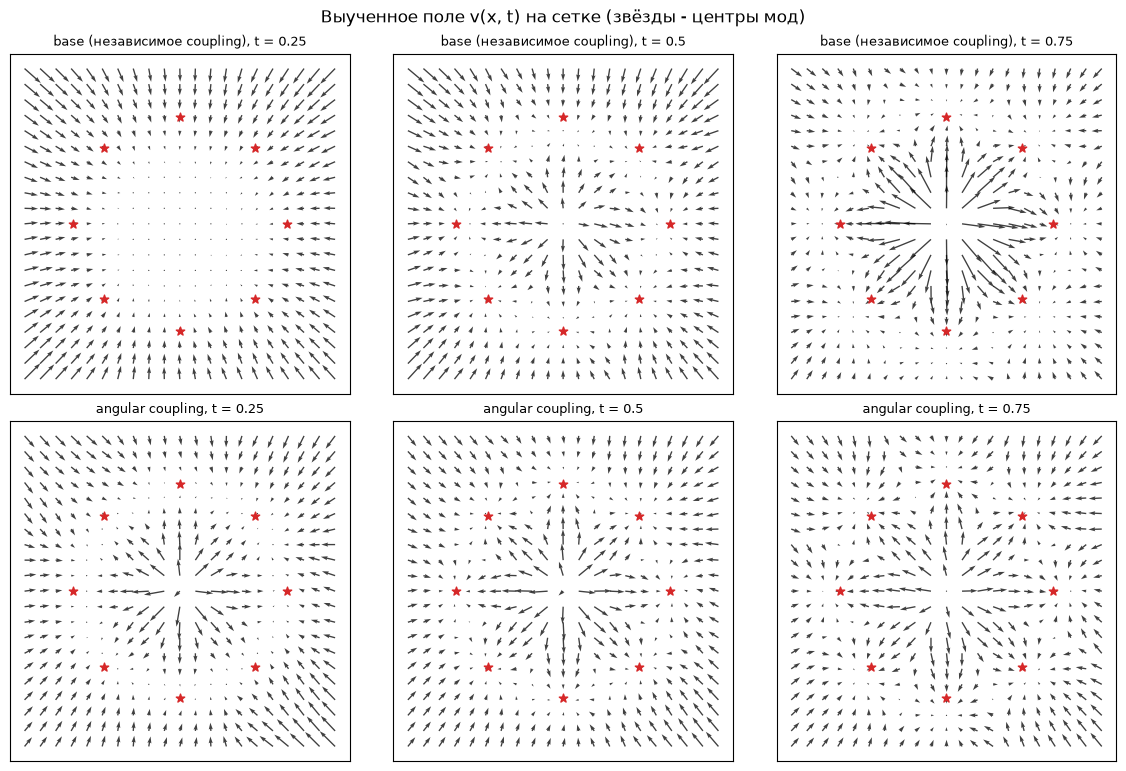

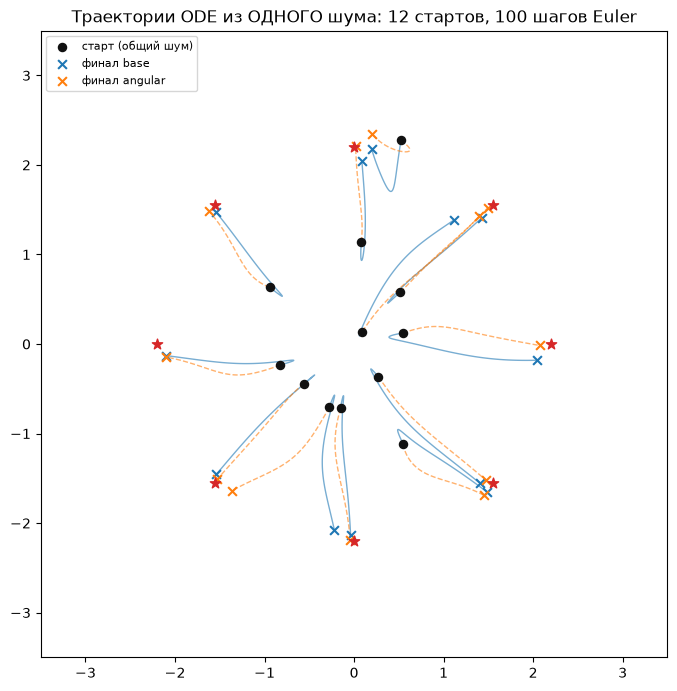

ЗАДАНИЕ 10 OK: quiver поля при t = 0.25/0.5/0.75 (base/angular) -> lab15_field_quiver.png; траектории 12 стартов из общего шума (100 шагов Euler) -> lab15_trajectories.png; те же старты: совпадение итоговой моды base vs angular 0.92, средний сдвиг финала 0.209 -> lab15_field_report.json


In [12]:
# ЗАДАНИЕ 10 - поле направлений (quiver) и траектории из того же исходного шума: base против angular.
model_flow.eval(); model_flow_ang.eval()
_grid = torch.linspace(-3.2, 3.2, 11 if FAST_DEV_RUN else 21)
_gx, _gy = torch.meshgrid(_grid, _grid, indexing='xy')
_grid_pts = torch.stack([_gx.ravel(), _gy.ravel()], 1)
_fields = []
for _tv in (0.25, 0.5, 0.75):
    _tt = torch.full((len(_grid_pts), 1), _tv, device=DEVICE)
    with torch.no_grad():
        _fields.append((_tv, model_flow(_grid_pts.to(DEVICE), _tt).cpu(),
                        model_flow_ang(_grid_pts.to(DEVICE), _tt).cpu()))

fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.6), constrained_layout=True)
for _r, _title in enumerate(['base (независимое coupling)', 'angular coupling']):
    for _c, (_tv, _fb, _fa) in enumerate(_fields):
        _f = _fb if _r == 0 else _fa
        _ax = axes[_r][_c]
        _ax.quiver(_grid_pts[:, 0], _grid_pts[:, 1], _f[:, 0], _f[:, 1], alpha=0.75, width=0.004)
        _ax.scatter(MODE_CENTERS[:, 0], MODE_CENTERS[:, 1], s=40, c='#d62728', marker='*', zorder=3)
        _ax.set_title(f'{_title}, t = {_tv}', fontsize=9)
        _ax.set_aspect('equal'); _ax.set_xlim(-3.5, 3.5); _ax.set_ylim(-3.5, 3.5)
        _ax.set_xticks([]); _ax.set_yticks([])
fig.suptitle('Выученное поле v(x, t) на сетке (звёзды - центры мод)')
fig.savefig(ARTIFACTS / 'lab15_field_quiver.png', dpi=125)
plt.show(); plt.close(fig)

_traj_starts = Z_EVAL[:(4 if FAST_DEV_RUN else 12)]
TRAJ_STEPS = 100
@torch.no_grad()
def trajectories(model, starts, steps=TRAJ_STEPS):
    # Путь каждой стартовой точки под ODE-интегрированием (Euler, steps шагов).
    dev = next(model.parameters()).device
    xs = [starts.clone()]
    x = starts.clone().to(dev)
    for _i in range(steps):
        t = torch.full((len(x), 1), _i / steps, device=dev)
        x = x + (1.0 / steps) * model(x, t)
        xs.append(x.cpu())
    return torch.stack(xs)

tr_base = trajectories(model_flow, _traj_starts)
tr_ang = trajectories(model_flow_ang, _traj_starts)
fig, ax = plt.subplots(figsize=(7.2, 6.8), constrained_layout=True)
for _j in range(len(_traj_starts)):
    ax.plot(tr_base[:, _j, 0], tr_base[:, _j, 1], '-', c='#1f77b4', alpha=0.6, lw=1)
    ax.plot(tr_ang[:, _j, 0], tr_ang[:, _j, 1], '--', c='#ff7f0e', alpha=0.6, lw=1)
ax.scatter(_traj_starts[:, 0], _traj_starts[:, 1], s=34, c='#111111', marker='o', zorder=3, label='старт (общий шум)')
ax.scatter(tr_base[-1, :, 0], tr_base[-1, :, 1], s=40, c='#1f77b4', marker='x', zorder=3, label='финал base')
ax.scatter(tr_ang[-1, :, 0], tr_ang[-1, :, 1], s=40, c='#ff7f0e', marker='x', zorder=3, label='финал angular')
for _k in range(8):
    ax.scatter(MODE_CENTERS[_k:_k + 1, 0], MODE_CENTERS[_k:_k + 1, 1], s=60, c='#d62728', marker='*', zorder=3)
ax.set_title(f'Траектории ODE из ОДНОГО шума: {len(_traj_starts)} стартов, {TRAJ_STEPS} шагов Euler')
ax.legend(fontsize=8, loc='upper left'); ax.set_aspect('equal')
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
fig.savefig(ARTIFACTS / 'lab15_trajectories.png', dpi=125)
plt.show(); plt.close(fig)

_end_b, _end_a = tr_base[-1], tr_ang[-1]
_ms_b, _ms_a = mode_stats(_end_b), mode_stats(_end_a)
_same_mode = float((_ms_b['assign'] == _ms_a['assign']).float().mean())
_mean_shift = float((_end_b - _end_a).norm(dim=1).mean())
save_json('lab15_field_report.json', {'traj_starts': int(len(_traj_starts)), 'traj_steps': TRAJ_STEPS,
          'grid_points': int(len(_grid_pts)), 't_values': [0.25, 0.5, 0.75],
          'base_coverage_traj_subset': round(_ms_b['coverage'], 4),
          'ang_coverage_traj_subset': round(_ms_a['coverage'], 4),
          'same_mode_share': round(_same_mode, 4), 'mean_endpoint_shift': round(_mean_shift, 4),
          'note': 'стартовые точки общие; расхождение финалов показывает влияние coupling на поле, '
                  'а не на маргинальное распределение'})
print(f'ЗАДАНИЕ 10 OK: quiver поля при t = 0.25/0.5/0.75 (base/angular) -> lab15_field_quiver.png; '
      f'траектории {len(_traj_starts)} стартов из общего шума ({TRAJ_STEPS} шагов Euler) -> lab15_trajectories.png; '
      f'те же старты: совпадение итоговой моды base vs angular {_same_mode:.2f}, средний сдвиг финала '
      f'{_mean_shift:.3f} -> lab15_field_report.json')

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [13]:
# БОНУС - творческое мини-исследование: гипотеза сформулирована ДО просмотра метрик на test.
# Гипотеза: вход t критично важен для rectified flow. Если убрать t из входа MLP (один фактор;
# данные, seed, бюджет и ширина сети - те же), поле выучивает усреднённое по времени направление,
# поэтому качество сэмплов по test ухудшится: покрытие мод упадёт, MMD вырастет при любом K.
model_flow_nt = VelocityMLP(use_time=False)
opt_nt = torch.optim.Adam(model_flow_nt.parameters(), lr=LR)
model_flow_nt.to(DEVICE)
history_nt = []
_t0 = time.time()
for _s in range(STEPS):
    history_nt.append(train_step(model_flow_nt, opt_nt, _s, 'flow'))
NT_TIME = round(time.time() - _t0, 1)
assert all(np.isfinite(history_nt)), 'NaN в loss бонус-модели'

BONUS_K = [1, 2] if FAST_DEV_RUN else [1, 5, 10, 100]
nt_rows = []
for _k in BONUS_K:
    _pts = euler_flow(model_flow_nt, Z_EVAL, _k).cpu()
    _row, _ = eval_sampler(f'rf_notime@{_k}', _pts, 0.0)
    nt_rows.append(_row)
_base_by_k = {r['sampler'].split('@')[1]: r for r in sampler_rows if r['sampler'].startswith('rf_euler')}
_cmp_k = '10' if '10' in _base_by_k else str(BONUS_K[-1])   # FULL: K=10; FAST: последний доступный
_b = _base_by_k[_cmp_k]
_n = next(r for r in nt_rows if r['sampler'].endswith('@' + _cmp_k))
BONUS_CONFIRMED = bool(_n['coverage'] < _b['coverage'] or _n['mmd2'] > _b['mmd2'])

_lines = ['# Бонус: абляция временного условия (use_time=False)', '',
          '- Гипотеза (сформулирована до измерений): без t на входе MLP поле усредняется по времени,',
          '  поэтому покрытие мод падает и MMD растёт при том же бюджете обучения.',
          f'- Контроль: те же {STEPS} шагов x batch {BATCH}, тот же train, тот же общий шум Z, тот же seed.',
          f'- Сравнение при K={_cmp_k}: base coverage {_b["coverage"]} / MMD {_b["mmd2"]}; '
          f'notime coverage {_n["coverage"]} / MMD {_n["mmd2"]}.',
          f'- Вердикт: гипотеза {"ПОДТВЕРЖДЕНА" if BONUS_CONFIRMED else "НЕ подтверждена"}.', '',
          '| K | покрытие base | покрытие notime | MMD base | MMD notime |', '|---|---|---|---|---|']
for _r in nt_rows:
    _kk = _r['sampler'].split('@')[1]
    _br = _base_by_k[_kk]
    _lines.append(f"| {_kk} | {_br['coverage']} | {_r['coverage']} | {_br['mmd2']} | {_r['mmd2']} |")
(ARTIFACTS / 'bonus.md').write_text('\n'.join(_lines) + '\n', encoding='utf-8')
save_json('bonus.json', {'hypothesis': 'без t на входе MLP поле усредняется по времени: покрытие мод падает, '
                        'MMD растёт при том же бюджете (данные/seed/шум/ширина сети без изменений)',
          'k_grid': BONUS_K, 'rows': nt_rows,
          'base_rows': [r for r in sampler_rows if r['sampler'].startswith('rf_euler')],
          'final_loss_nt': round(history_nt[-1], 6), 'train_time_s': NT_TIME, 'confirmed': BONUS_CONFIRMED,
          'note': 'test использован только для итогового сравнения, выбор настройки по test не проводился'})
print(f'БОНУС OK: use_time=False обучена ({STEPS} шагов, loss {round(history_nt[0], 4)} -> '
      f'{round(history_nt[-1], 6)}; {NT_TIME} c); при K={_cmp_k}: покрытие base {_b["coverage"]} vs notime '
      f'{_n["coverage"]}, MMD {_b["mmd2"]} vs {_n["mmd2"]}; гипотеза '
      f'{"ПОДТВЕРЖДЕНА" if BONUS_CONFIRMED else "НЕ подтверждена"} -> bonus.json + bonus.md')

БОНУС OK: use_time=False обучена (3000 шагов, loss 3.5887 -> 2.924955; 6.1 c); при K=10: покрытие base 1.0 vs notime 1.0, MMD 0.000318 vs 0.000824; гипотеза ПОДТВЕРЖДЕНА -> bonus.json + bonus.md


## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

## Итоги выполнения

> Заполняется по факту полного прогона (`FAST_DEV_RUN=False`); FAST-прогон в отчёт не включается.

**Протокол.** Устройство: cuda - NVIDIA GeForce GTX 1050 Ti, cc 6.1; версии: torch 2.14.1+cu126, numpy 2.4.6. Данные: 8 гауссовых мод на окружности (радиус 2.2, sigma 0.12); train 4096 / test 4096 точек, независимые выборки (seed 43 / 44); prior N(0, I) общий для всех моделей и сэмплеров. Модели: VelocityMLP 3->128->128->128->2 (по 33794 параметров у flow и VP - поровну), Adam lr 0.001; равный бюджет: 3000 optimizer steps на модель, batch 256, общее расписание батчей, t и шума; VP-cap t <= 0.9 (без сингулярной точки t = 1). Сетка шагов Euler: K = 1, 2, 5, 10, 25, 100.

**Обучение.** Финальный loss: flow 2.046918, VP 0.440544, angular 0.202082, бонус без t 2.924955 (loss flow и VP НЕ сравниваются напрямую - разные таргеты: скорость v* = x1 - x0 против eps). Checkpoints: `lab15/ckpt_flow.pt`, `lab15/ckpt_vp.pt`, `lab15/ckpt_flow_ang.pt` (model + optimizer + step + история); resume-проверка: выход свежей модели после load_state_dict совпадает с обученной (max|d| = 0.00e+00).

**Сэмплеры (N = 4096 сэмплов из общего шума Z).**

| сэмплер | шаги K | покрытие мод | MMD^2 | среднее dist до test |
|---|---|---|---|---|
| RF Euler | 1 | 1.000 | 0.08399 | 1.604 |
| RF Euler | 5 | 1.000 | 0.00089 | 0.092 |
| RF Euler | 25 | 1.000 | 0.00010 | 0.039 |
| RF Euler | 100 | 1.000 | 0.00003 | 0.033 |
| VP reverse | 1 | 0.875 | 0.08196 | 0.990 |
| VP reverse | 5 | 1.000 | 0.00842 | 0.070 |
| VP reverse | 25 | 1.000 | 0.00301 | 0.034 |
| VP reverse | 100 | 1.000 | 0.00252 | 0.028 |

Полная сетка K и время каждой конфигурации: `lab15_samplers_summary.json`.

**Coupling (угловой pairing, тот же бюджет).** покрытие мод при K = 1: base 1.000 против angular 1.000; при K = 100: 1.000 против 1.000; влияние на поле при одинаковых стартах: совпадение итоговой моды 0.92, средний сдвиг финала 0.209.

**Бонус (модель без временного входа).** Гипотеза: вход t критично важен для rectified flow - без t поле выучивает усреднённое по времени направление, поэтому качество сэмплов по test ухудшается: покрытие мод падает и MMD растёт при том же бюджете; сформулирована до измерений. Результат при K = 10: покрытие мод 1.0 у бонус-модели против 1.0 у базовой, MMD 0.000824 у бонус-модели против 0.000318 у базовой; гипотеза ПОДТВЕРЖДЕНА - по росту MMD при том же полном покрытии (артефакты: `bonus.json`, `bonus.md`).

**Худшие случаи.** 5 сэмплов RF@100, наиболее удалённых от test; расстояния до ближайшей test-точки: 0.5404, 0.5145, 0.5127, 0.5090, 0.5083; ранги 1-5 по убыванию, все 5 точек в межмодовых областях - до ближайшего центра моды 0.84-0.90 при sigma 0.12 (координаты и ближайшие моды - `lab15_worst5.json`).

**Время этапов.** данные не хронометрировались; обучение flow + VP 13.6 c; обучение angular 6.2 c; бонус-модель 6.1 c; оценка сэмплеров ~0.35 c (сумма времён 12 конфигураций сетки); всего не хронометрировалось (три этапа обучения - 13.6 + 6.2 + 6.1 = 25.9 c).

**Ключевой вывод.** Rectified flow с линейными путями достигает низкого MMD^2 за единицы шагов Euler: RF@5 - 0.00089 при полном покрытии 8/8, тогда как VP при том же бюджете даже при K = 100 даёт лишь 0.00252 (хуже RF@5 в ~3 раза), а при K = 1 теряет одну из 8 мод (7/8). Угловой pairing при том же бюджете ускоряет few-step сэмплирование на порядки: MMD^2 при K = 1 - 0.08399 против 0.00254 (~x33), при K = 2 - 0.02941 против 0.00013, при полном покрытии у обеих моделей; поля при общих стартах близки (совпадение итоговой моды 0.92, средний сдвиг финала 0.209). Абляция подтверждает критичность условия t: без него MMD^2 при K = 10 растёт 0.000318 -> 0.000824 при том же покрытии. Loss flow и VP не сравниваются напрямую - разные таргеты (v* = x1 - x0 против eps), поэтому модели сопоставляются только по качеству сэмплов на test.